<a href="https://colab.research.google.com/github/QuirozAlaniz/Regresion_Lineal_Multiple/blob/main/PracticaRegresionLinealMultiple.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Maestría en Inteligencia Artificial y Analítica de Datos

## Programación para Analítica Descriptiva y Predictiva - Octubre 2026
## Práctica: Práctica: Regresión Lineal Múltiple
---


## Datos del Estudiante

*   Apellidos y Nombre: Quiroz Alaniz Francisco Daniel
*   Matrícula: 269723

---



##  Objetivo de aprendizaje
Al finalizar esta práctica, el estudiante será capaz de **aplicar regresión lineal múltiple utilizando Scikit-Learn para modelar la relación entre varias variables independientes y una variable dependiente**, verificar los supuestos del modelo, interpretar los coeficientes, analizar la correlación entre predictores y evaluar el rendimiento del modelo utilizando métricas como el MSE, RMSE y R².

Datos
Trabajarás con el archivo `advertising.csv`, que contiene información sobre el gasto publicitario en diferentes medios y las ventas obtenidas:

-`TV`: inversión en publicidad televisiva.

-`Radio`: inversión en publicidad en radio.

-`Newspaper`: inversión en publicidad en periódicos.

`Sales`: ventas del producto (variable dependiente).

## Parte 1: Carga de datos y bibliotecas
1. Importa las bibliotecas necesarias.
2. Carga el archivo `advertising.csv`.
3. Muestra las primeras filas del dataframe.
4. Describe estadísticamente las variables.

In [241]:
# Tu código aquí
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
import statsmodels.api as sm
from sklearn.linear_model import LinearRegression
from sklearn import datasets
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from scipy import stats

In [242]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [243]:
ruta = "/content/drive/MyDrive/UACJ/Programacion Desc Predict UACJ/20. Sesion 20/2/advertising.csv"
df = pd.read_csv(ruta)
print(df.head())

      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3   12.0
3  151.5   41.3       58.5   16.5
4  180.8   10.8       58.4   17.9


In [244]:
#Descripción estadística de las variables
df.describe()

,TV,Radio,Newspaper,Sales
count,200.000000,200.000000,200.000000,200.000000
mean,147.042500,23.264000,30.554000,15.130500
std,85.854236,14.846809,21.778621,5.283892
min,0.700000,0.000000,0.300000,1.600000
25%,74.375000,9.975000,12.750000,11.000000
50%,149.750000,22.900000,25.750000,16.000000
75%,218.825000,36.525000,45.100000,19.050000
max,296.400000,49.600000,114.000000,27.000000


## Parte 2: Análisis exploratorio de los datos
### 2.1  Análisis de la Relación Lineal entre la variable dependiente y las independientes
1. Grafica dispersión entre cada variable independiente (`TV`, `Radio`, `Newspaper`) y `Sales`. Usa también regplot.
2. Interpreta visualmente la relación entre variables.

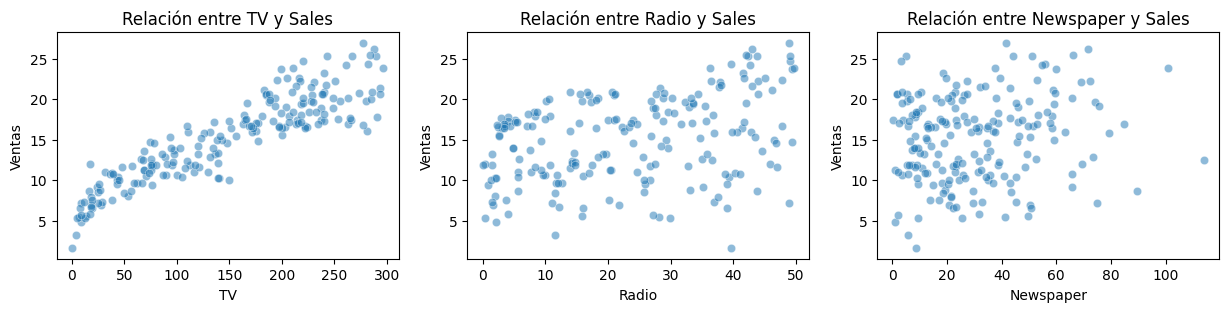

In [245]:
# 4. Visualización de scatterplots entre todas las características y la variable objetivo 'Sales'
plt.figure(figsize=(15, 10))
for i, column in enumerate(df.columns[:-1]):  # Excluimos la columna 'Sales'
    plt.subplot(3, 3, i+1)
    sns.scatterplot(x=df[column], y=df['Sales'], alpha=0.5)
    plt.title(f"Relación entre {column} y Sales")
    plt.xlabel(column)
    plt.ylabel("Ventas")

<Axes: xlabel='TV', ylabel='Sales'>

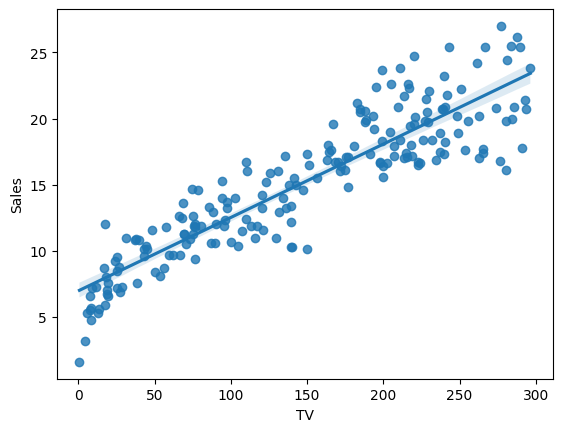

In [246]:
#Usando regplot
sns.regplot(data = df, x = "TV", y = "Sales")

<Axes: xlabel='Radio', ylabel='Sales'>

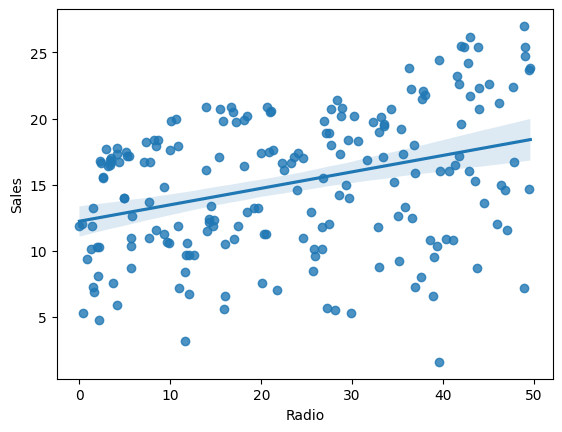

In [247]:
#Usando regplot
sns.regplot(data = df, x = "Radio", y = "Sales")

<Axes: xlabel='Newspaper', ylabel='Sales'>

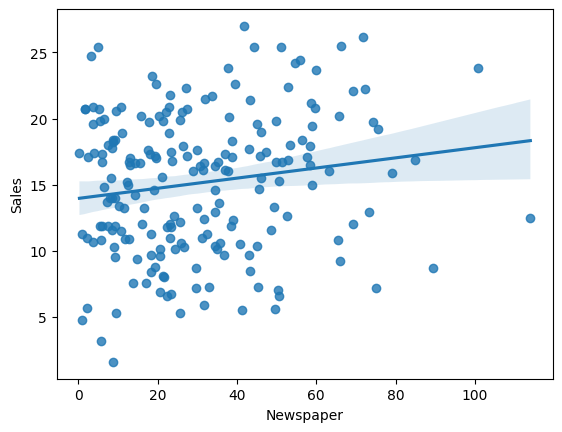

In [248]:
#Usando regplot
sns.regplot(data = df, x = "Newspaper", y = "Sales")

### 2.2: Correlación entre variables
1. Calcula la matriz de correlación.
2. Visualízala con un heatmap.
3. Responde: ¿Qué variables están más correlacionadas con `Sales`? ¿Hay correlación alta entre predictores?

<Axes: >

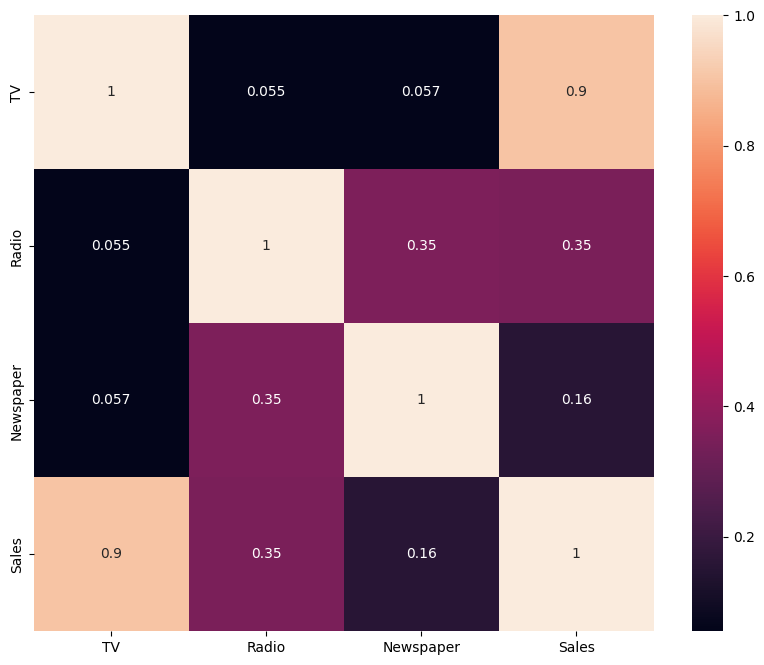

In [249]:
# Correlación y heatmap
corr = df.corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot = True)

Es claro que La inversión en publicidad televisiva está correlacionada fuertemente (0.9) con las ventas mientras que la inversión en Newspaper está muy poco relacionada con las ventas (0.16) y con la inversión en radio un poco más (0.35).
\
Con respecto a la correlación entre las variables que no son Sales, podemos ver que está correlacionada la inversión en Radio con la inversión con Newspaper (0.35) y muy poco con la inversión en Televisión (0.055). También la correlación entre inversión en televisión y newspaper es muy baja (0.057).

## Parte 3. Multicolinealidad
1. Calcula el VIF (Variance Inflation Factor) para cada predictor.
2. Crea un diagrama de barras  para mostrar el  VIF
3. Interpreta si hay multicolinealidad:
- ¿Alguna variable tiene un VIF mayor a 5 o mayor a 10?
- ¿Qué implicaciones tiene esto para el modelo?


### Análisis de Multicolinealidad ###
    Variable       VIF
0      const  1.000000
1         TV  1.004611
2      Radio  1.144952
3  Newspaper  1.145187


/tmp/ipykernel_893/1691308800.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='VIF', y='Variable', data=vif_data, palette='coolwarm')


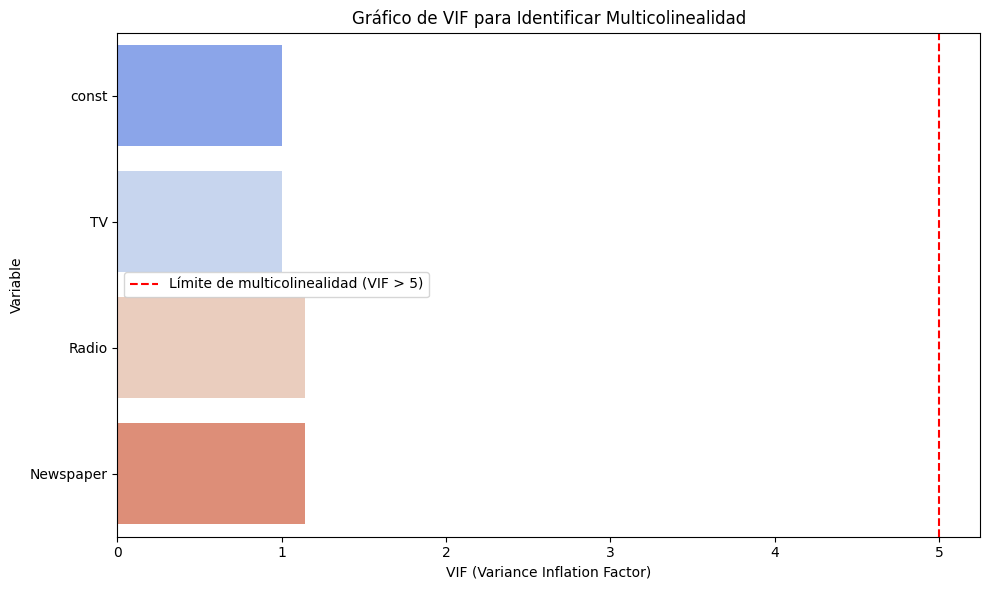

In [250]:
X = add_constant(df.drop(columns=['Sales']))  # Matriz de características sin la variable dependiente
vif_data = pd.DataFrame()
vif_data['Variable'] = X.columns
vif_data['VIF'] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
print("\n### Análisis de Multicolinealidad ###")
print(vif_data)


# 7. Visualización de VIF
plt.figure(figsize=(10, 6))
sns.barplot(x='VIF', y='Variable', data=vif_data, palette='coolwarm')
plt.axvline(x=5, color='red', linestyle='--', label='Límite de multicolinealidad (VIF > 5)')
plt.xlabel('VIF (Variance Inflation Factor)')
plt.title('Gráfico de VIF para Identificar Multicolinealidad')
plt.legend()
plt.tight_layout()
plt.show()

Podemos observar que ningún valor VIF es mayor a 5, por lo que no hay problema de colinealidad entre las variables predictoras.
\
Esto implica que no hay evidencia de multicolinealidad importante entre las variables predictoras

## Parte 4: Construcción del Modelo (Todas las variables Independientes), Evaluación

### 4.1 Entrenamiento del Modelo (Todas las Variables Independientes)

1. Entrena un modelo de regresión lineal múltiple usando TV, Radio y Newspaper como variables independientes.
2. Imprime el intercepto y los coeficientes del modelo.
3. Interpreta cada uno:
¿Qué significa cada uno de los coeficientes  en términos de ventas?

In [251]:
X = df.drop(columns='Sales')  # Características
y = df['Sales']  # Variable dependiente (ventas)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
model = LinearRegression()
model.fit(X_scaled,y)

LinearRegression()

In [252]:
# 2. Imprimir el intercepto y los coeficientes asociados a cada predictor
print(f"Intercepto (Beta 0): {model.intercept_:.4f}")
print("-" * 40)
for col, coef in zip(X.columns, model.coef_):
    print(f"Coeficiente para {col}: {coef:.4f}")

Intercepto (Beta 0): 15.1305
----------------------------------------
Coeficiente para TV: 4.6627
Coeficiente para Radio: 1.5847
Coeficiente para Newspaper: 0.0073


In [253]:
coefficients = model.coef_
intercept = model.intercept_

print(f"\nCoeficientes estimados: {coefficients}")
print(f"Término independiente estimado: {intercept}")
#######################################################
print('\n')
equation = f"Sales = {intercept} "
for i, coef in enumerate(coefficients):
  equation += f"+ ({coef} * {X.columns[i]}) "

equation #se obtiene el modelo con los coeficientes


Coeficientes estimados: [4.66270025 1.58465027 0.00729187]
Término independiente estimado: 15.130500000000001




'Sales = 15.130500000000001 + (4.662700245086694 * TV) + (1.5846502733236385 * Radio) + (0.0072918683037688226 * Newspaper) '

### 4.2 Normalidad de los residuos

1. Calcula los residuos: residuos = y - y_pred.

2. Grafica un histograma con KDE de los residuos.

3. ¿Los residuos parecen distribuirse normalmente?

In [254]:
#Normalidad de los residuos
y_pred = model.predict(X_scaled)
residuos = y - y_pred
print(residuos)

0      0.879028
1     -0.868248
2      1.503791
3     -0.812447
4      2.255863
         ...   
195    0.494510
196    3.719059
197   -0.459287
198    0.917780
199    0.214880
Name: Sales, Length: 200, dtype: float64


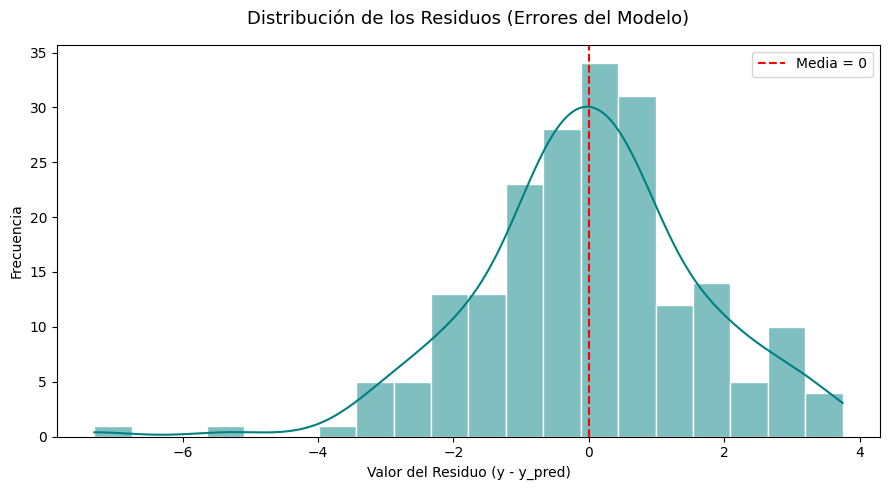

In [255]:
# 2. Graficar el histograma con la curva de densidad (KDE)
plt.figure(figsize=(9, 5))
sns.histplot(residuos, kde=True, color='teal', bins=20, edgecolor='white')

# Añadir elementos estéticos
plt.axvline(x=0, color='red', linestyle='--', linewidth=1.5, label='Media = 0')
plt.title('Distribución de los Residuos (Errores del Modelo)', fontsize=13, pad=15)
plt.xlabel('Valor del Residuo (y - y_pred)')
plt.ylabel('Frecuencia')
plt.legend()
plt.tight_layout()
plt.show()

Los residuos visualmente se distribuyen de manera Normal con una ligera cola larga a la izquierda

### 4.3. Homocedasticidad

1. Grafica los residuos contra los valores predichos.
2. ¿Observas patrones? ¿Los residuos se dispersan aleatoriamente?

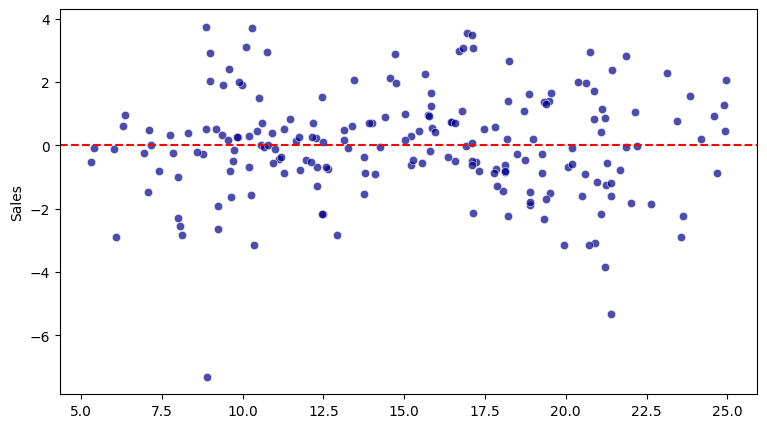

In [256]:
# Homocedasticidad
plt.figure(figsize=(9, 5))

# 1. Graficar la dispersión de predichos vs residuos
sns.scatterplot(x=y_pred, y=residuos, color='darkblue', alpha=0.7)

# Añadir una línea de referencia en Y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5, label='Residuo = 0')

Los residuos no siguen un patrón definido, se distribuyen de manera equilibrada, lo cual implica que el modelo es válido y no hay problema de precisión para diferentes valores

### 4.4 Q-Q Plot

1. Graficar el Q-Q Plot
2. Interpreta el gráfico: a) Si los puntos se alinean aproximadamente sobre la línea diagonal, los residuos siguen una distribución normal, b) Desviaciones sistemáticas indican asimetría o colas pesadas.

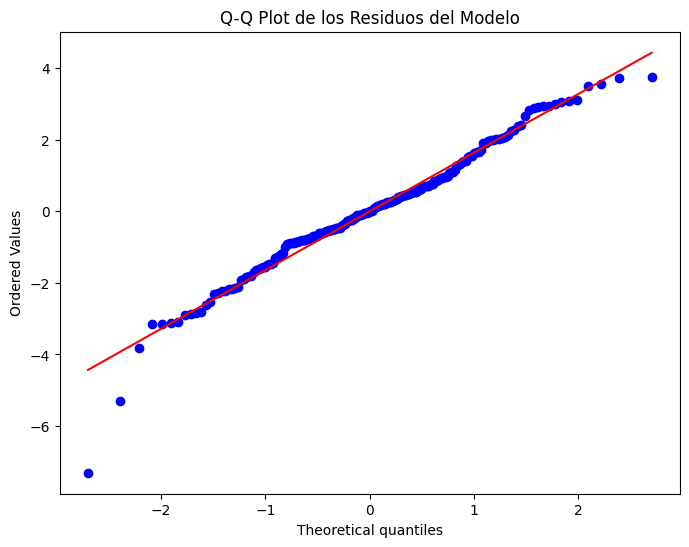

In [257]:
#Q-Q Plot
#. Graficar el Q-Q Plot
plt.figure(figsize=(8, 6))
stats.probplot(residuos, dist="norm", plot=plt)

# Añadir título
plt.title("Q-Q Plot de los Residuos del Modelo")

# Mostrar la gráfica
plt.show()

La gran mayoría de los datos en el QQplot se centran sobre la línea diagonal, solo algunos cuantos (los menos) se salen de esa línea. Esto significa que los erroes sí siguen una distribución Normal, que es un supuesto del modelo.

### 4.5. Evaluación del Modelo

1. Calcula las métricas: a) MSE (error cuadrático medio), b) RMSE (raíz del error cuadrático medio), c) R² (coeficiente de determinación)

2. ¿Qué nos dicen estas métricas sobre el ajuste del modelo?


In [258]:
#Evaluación del Modelo
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# 13. Calcular las métricas del modelo
mse = mean_squared_error(y, y_pred)  # Error cuadrático medio
rmse = np.sqrt(mse)  # Raíz del error cuadrático medio
mae = mean_absolute_error(y, y_pred)  # Error absoluto medio
r2 = r2_score(y, y_pred)  # Coeficiente de determinación R^2

# 14. Mostrar las métricas
print(f"Error Cuadrático Medio (MSE): {mse:.4f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse:.4f}")
print(f"Error Absoluto Medio (MAE): {mae:.4f}")
print(f"Coeficiente de Determinación (R²): {r2:.4f}")


Error Cuadrático Medio (MSE): 2.7060
Raíz del Error Cuadrático Medio (RMSE): 1.6450
Error Absoluto Medio (MAE): 1.2364
Coeficiente de Determinación (R²): 0.9026


El error cuadrático medio es 2.7
\
La Raíz del error cuadrático medio no es más que la raíz cuadrada del anterior.
\
El error absoluto medio de 1.23 significa que cada predicción difiere en 1.23 unidades en promedio.
\
Como el coeficiente de determinación es .9026, significa que explica el 90.26% de variabilidad, lo cual es un buen nivel.


### 4.6. Visualización de Predicciones

1. Crea un gráfico comparando Sales reales vs Sales predichas.

2. Puedes usar plt.scatter(y_true, y_pred) para evaluar visualmente el ajuste.

3. ¿Qué observas? ¿Qué información puedes obtener de esta gráfica?

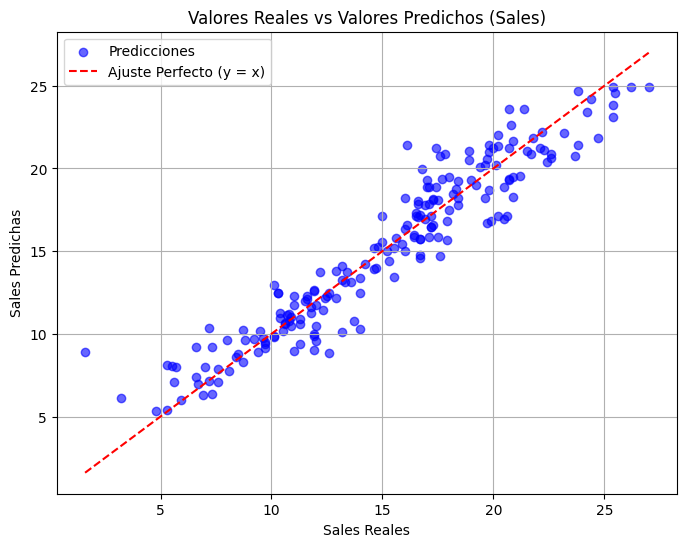

In [259]:
#Visualización de las Predicciones
plt.figure(figsize=(8, 6))
plt.scatter(y, y_pred, alpha=0.6, color="blue", label="Predicciones")

# Línea de referencia ideal (donde y_real == y_pred)
min_val = min(min(y), min(y_pred))
max_val = max(max(y), max(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", label="Ajuste Perfecto (y = x)")

plt.xlabel("Sales Reales")
plt.ylabel("Sales Predichas")
plt.title("Valores Reales vs Valores Predichos (Sales)")
plt.legend()
plt.grid(True)
plt.show()

Se puede observar en la gráfica que gran parte de las ventas predichas se ajustan considerablemente bien a las ventas reales, aunque hay algunos valores que difieren o se alejan de lo real.

### 4.7 Verificar el impacto de los atributos en el modelo

1. Ajusta el modelo usando statsmodels en lugar de scikit-learn para obtener los valores p.
2. Interpreta los resultados:

 - Observa los valores P>|t| en la tabla de salida.

 - ¿Qué variables tienen p-value menores a 0.05?

 - ¿Cuál es la conclusión sobre esas variables?


In [260]:
#P-values
# 1. Agregar la constante (intercepto) a las variables independientes
X_constant = sm.add_constant(X)

# 2. Ajustar el modelo OLS (Ordinary Least Squares)
model_sm = sm.OLS(y, X_constant).fit()

# 3. Imprimir el resumen estadístico
print(model_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                     605.4
Date:                Sat, 31 Oct 2026   Prob (F-statistic):           8.13e-99
Time:                        18:51:40   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             774.7
Df Residuals:                     196   BIC:                             787.9
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6251      0.308     15.041      0.0

Podemos observar que todas las variables predictoras tienen un P-valor menor al nivel de significancia 0.05 a excepción de Newspaper que tiene 0.954, lo que significa que no es estadísticamente significativa, pues ya veíamos antes que la correlación entre la inversión en Newspaper y Sales es bajísima.
\
Por otro lado TV y Radio, al ser menores a 0.05, sí tienen relevancia significativa para el modelo.

##Parte 5:  Construcción del Modelo (sin Multicolinealidad), Evaluación

En el caso de que hayas detectado variables con multicolinealidad. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

En este caso no es necesario hacer un nuevo modelo porque no hay multicolineadlidad entre las variables predictoras como se vió en la sección 2.2 de correlación entre variables predictoras.

## Parte 6: Construcción del Modelo (sin variables que no muestran una relación lineal), Evaluación

En el caso de que hayas detectado variables sin una relación lineal con la variable dependiente. Elimina aquellas que presenten esta característica y realiza lo siguiente.

En el caso de que hayas detectado variables sin una relación lineal. Elimina aquellas que presenten esta característica y realiza los mismos pasos** que la parte 4.**
Escribe cada una de las subsecciones similares a las existentes en la Parte 4.

In [261]:
X = df.drop(columns=['Sales', "Newspaper"])  # Características sin Newspaper
y = df['Sales']  # Variable dependiente (ventas)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
model3 = LinearRegression()
model3.fit(X_scaled,y)

LinearRegression()

Hacemos un nuevo modelo pero sin la variable Newspaper porque esa variable tiene una correlación muy baja con la variable Sales por lo que es estadísticamente no significativa.

In [262]:
# 2. Imprimir el intercepto y los coeficientes asociados a cada predictor
print(f"Intercepto (Beta 0): {model3.intercept_:.4f}")
print("-" * 40)
for col, coef in zip(X.columns, model3.coef_):
    print(f"Coeficiente para {col}: {coef:.4f}")

Intercepto (Beta 0): 15.1305
----------------------------------------
Coeficiente para TV: 4.6630
Coeficiente para Radio: 1.5872


In [263]:
coefficients = model3.coef_
intercept = model3.intercept_

print(f"\nCoeficientes estimados: {coefficients}")
print(f"Término independiente estimado: {intercept}")
#######################################################
print('\n')
equation = f"Sales = {intercept} "
for i, coef in enumerate(coefficients):
  equation += f"+ ({coef} * {X.columns[i]}) "

equation #se obtiene el modelo con los coeficientes


Coeficientes estimados: [4.66297261 1.58721742]
Término independiente estimado: 15.130500000000001




'Sales = 15.130500000000001 + (4.662972611875511 * TV) + (1.5872174231801197 * Radio) '

Obtuvimos la nueva función con el intercepto, la variable TV con su coeficiente y la variable Radio también con su coeficiente

In [264]:
#Normalidad de los residuos
y_pred = model3.predict(X_scaled)
residuos = y - y_pred
print(residuos)

0      0.889216
1     -0.865819
2      1.513286
3     -0.806207
4      2.267263
         ...   
195    0.492624
196    3.714873
197   -0.465069
198    0.926063
199    0.209815
Name: Sales, Length: 200, dtype: float64


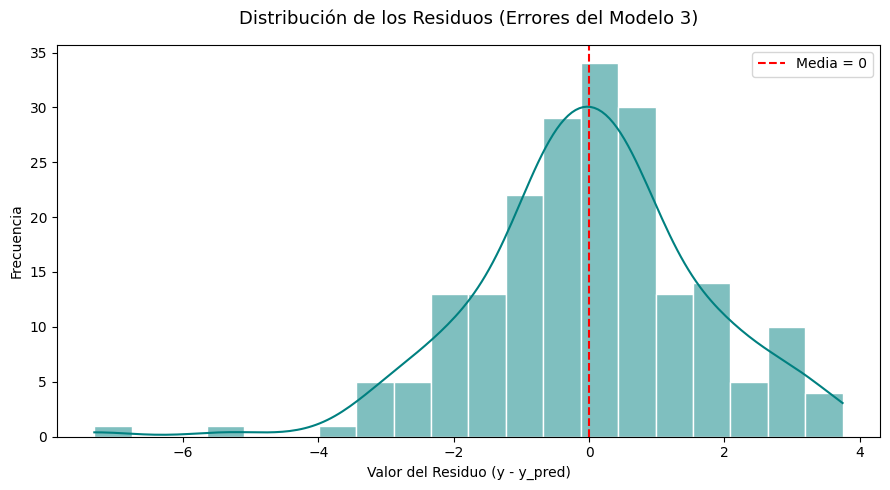

In [265]:
# 2. Graficar el histograma con la curva de densidad (KDE)
plt.figure(figsize=(9, 5))
sns.histplot(residuos, kde=True, color='teal', bins=20, edgecolor='white')

# Añadir elementos estéticos
plt.axvline(x=0, color='red', linestyle='--', linewidth=1.5, label='Media = 0')
plt.title('Distribución de los Residuos (Errores del Modelo 3)', fontsize=13, pad=15)
plt.xlabel('Valor del Residuo (y - y_pred)')
plt.ylabel('Frecuencia')
plt.legend()
plt.tight_layout()
plt.show()

Al verificar visualmente la distribución de los errores, vemos que sí tiene la fomra de la camapana de gauss, lo cual indica una distribución Normal.

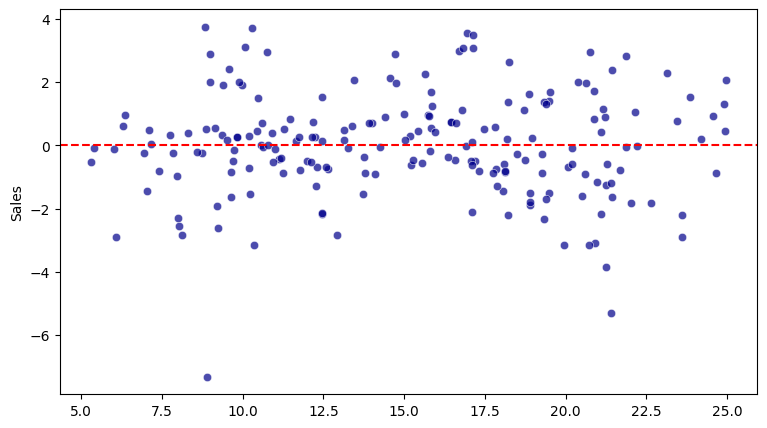

In [266]:
# Homocedasticidad
plt.figure(figsize=(9, 5))

# 1. Graficar la dispersión de predichos vs residuos
sns.scatterplot(x=y_pred, y=residuos, color='darkblue', alpha=0.7)

# Añadir una línea de referencia en Y=0
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5, label='Residuo = 0')

También observamos que los errores se distribuyen aleatoriamente sin un patrón fijo claro.

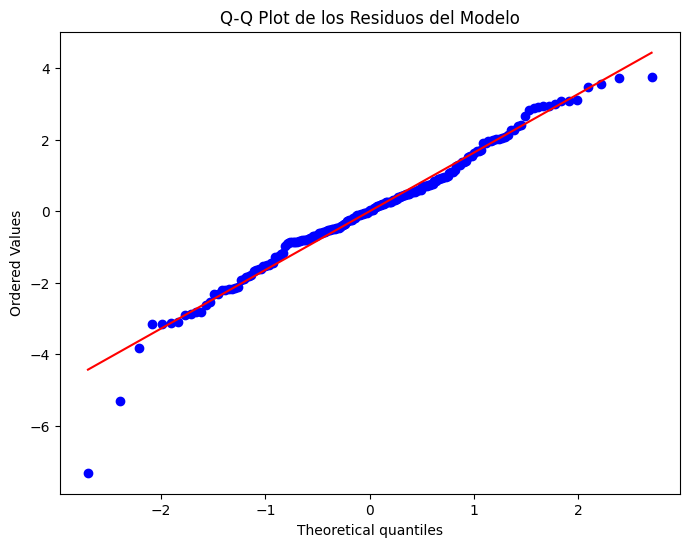

In [267]:
#Q-Q Plot
#. Graficar el Q-Q Plot
plt.figure(figsize=(8, 6))
stats.probplot(residuos, dist="norm", plot=plt)

# Añadir título
plt.title("Q-Q Plot de los Residuos del Modelo")

# Mostrar la gráfica
plt.show()

Al igual que en el primer modelo con todas las variables predictoras, se observa un gran ajuste a la Normal aunque también con algunos valores que se alejan significativamente de la diagonal.

In [268]:
#Evaluación del Modelo
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# 13. Calcular las métricas del modelo
mse = mean_squared_error(y, y_pred)  # Error cuadrático medio
rmse = np.sqrt(mse)  # Raíz del error cuadrático medio
mae = mean_absolute_error(y, y_pred)  # Error absoluto medio
r2 = r2_score(y, y_pred)  # Coeficiente de determinación R^2

# 14. Mostrar las métricas
print(f"Error Cuadrático Medio (MSE): {mse:.4f}")
print(f"Raíz del Error Cuadrático Medio (RMSE): {rmse:.4f}")
print(f"Error Absoluto Medio (MAE): {mae:.4f}")
print(f"Coeficiente de Determinación (R²): {r2:.4f}")


Error Cuadrático Medio (MSE): 2.7061
Raíz del Error Cuadrático Medio (RMSE): 1.6450
Error Absoluto Medio (MAE): 1.2368
Coeficiente de Determinación (R²): 0.9026


Comparando el error cuadrático Medio con el modelo anterior, vemos que casi no difiere, lo cual significa que tampoco la Raíz del Error Cuadrático Medio.
\
El error absoluto medio es de hecho muy similar al igual que el Coeficiente de Determinación.
\
Esto confirma que el modelo casi no mejora ni empeora si no tomamos Newspaper como variable predictora, confirmando también su irrelevancia estadística.

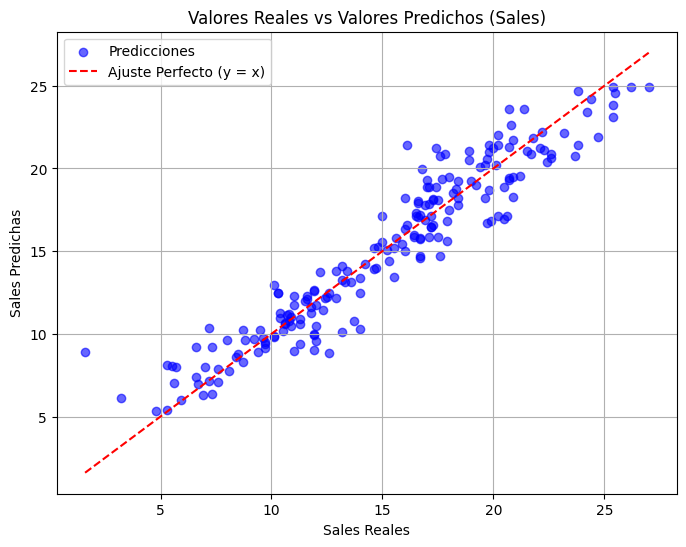

In [269]:
#Visualización de las Predicciones
plt.figure(figsize=(8, 6))
plt.scatter(y, y_pred, alpha=0.6, color="blue", label="Predicciones")

# Línea de referencia ideal (donde y_real == y_pred)
min_val = min(min(y), min(y_pred))
max_val = max(max(y), max(y_pred))
plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", label="Ajuste Perfecto (y = x)")

plt.xlabel("Sales Reales")
plt.ylabel("Sales Predichas")
plt.title("Valores Reales vs Valores Predichos (Sales)")
plt.legend()
plt.grid(True)
plt.show()

Observamos que al igual que en el primer modelo, los valores predichos versus los valores reales están muy cerca, con algunos valores alejados en los extremos.

In [270]:
#P-values
# 1. Agregar la constante (intercepto) a las variables independientes
X_constant = sm.add_constant(X)

# 2. Ajustar el modelo OLS (Ordinary Least Squares)
model_sm = sm.OLS(y, X_constant).fit()

# 3. Imprimir el resumen estadístico
print(model_sm.summary())

                            OLS Regression Results                            
Dep. Variable:                  Sales   R-squared:                       0.903
Model:                            OLS   Adj. R-squared:                  0.902
Method:                 Least Squares   F-statistic:                     912.7
Date:                Sat, 31 Oct 2026   Prob (F-statistic):          2.39e-100
Time:                        18:51:41   Log-Likelihood:                -383.34
No. Observations:                 200   AIC:                             772.7
Df Residuals:                     197   BIC:                             782.6
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          4.6309      0.290     15.952      0.0

##7. Conclusiones.

¿Cuál de los tres modelos construidos fue el mejor?
¿Cuál fue el atributo que mas influencia tiene en las ventas?

El mejor modelo es el último donde usé solo dos variables predictoras: Radio y TV, el cual excluye la variable Newspaper por su falta de significancia estadística. Al evaluar su rendimiento contra el modelo completo, observamos que las métricas de precisión se mantienen idénticas ($R^2$ de 0.9026 y RMSE de 1.6450). Entonces por ser más simple y tener las mismas métricas lo prefiero sobre el primero que usa las tres variables predictoras.
\
\
El atributo con mayor peso e influencia sobre las ventas es la inversión en TV. Esto lo podemos ver en la ecuación, el coeficiente de Radio es de 1.58 mientras que el de TV es 4.66. Esto significa que por cada aumento de una desviación estándar en el presupuesto de TV, el retorno en ventas se multiplica casi tres veces más que con el mismo incremento en radio.
